# Software Ticket Resolution Time Prediction

## 1. Objective

The objective of this lab is to build a prototype that predicts software support ticket resolution time using a synthetic dataset.

I will compare a mean baseline, Linear Regression, Polynomial Regression, Ridge Regression, and Lasso Regression using MAE, RMSE, and R². I will use cross-validation to select model settings, inspect residual plots, and discuss potential data leakage and limitations.

The dataset is synthetic, so the results should not be assumed to represent a real software organization.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load and Inspect the Dataset

Before building a model, I will inspect the dataset to understand its size, column types, statistical summaries, missing values, and sample records.

In [2]:
df = pd.read_csv("lab_ticket_resolution.csv")

print("Dataset shape:")
print(df.shape)

print("\nData types:")
print(df.dtypes)

print("\nDescriptive statistics:")
display(df.describe(include="all"))

print("\nMissing values:")
print(df.isna().sum())

print("\nFirst five rows:")
display(df.head())

Dataset shape:
(240, 6)

Data types:
ticket_id                    str
complexity_score           int64
lines_changed              int64
team_experience_years    float64
reopened                   int64
resolution_hours         float64
dtype: object

Descriptive statistics:


,ticket_id,complexity_score,lines_changed,team_experience_years,reopened,resolution_hours
count,240,240.000000,240.000000,240.000000,240.000000,240.000000
unique,240,NaN,NaN,NaN,NaN,NaN
top,T0001,NaN,NaN,NaN,NaN,NaN
freq,1,NaN,NaN,NaN,NaN,NaN
mean,NaN,5.491667,54.820833,6.105417,0.233333,19.361125
std,NaN,2.979697,26.145017,3.391426,0.423836,10.035058
min,NaN,1.000000,1.000000,0.500000,0.000000,0.500000
25%,NaN,3.000000,33.000000,3.300000,0.000000,11.015000
50%,NaN,5.500000,54.000000,5.800000,0.000000,19.610000
75%,NaN,8.000000,74.000000,9.200000,0.000000,27.122500



Missing values:
ticket_id                0
complexity_score         0
lines_changed            0
team_experience_years    0
reopened                 0
resolution_hours         0
dtype: int64

First five rows:


,ticket_id,complexity_score,lines_changed,team_experience_years,reopened,resolution_hours
0,T0001,6,67,5.6,1,24.77
1,T0002,9,72,11.5,0,33.43
2,T0003,6,49,3.3,0,17.82
3,T0004,5,50,9.6,1,19.54
4,T0005,3,33,6.4,1,11.04


## 3. Define the Features and Target

The target variable (y) is `resolution_hours`, because the goal is to predict ticket resolution time.

The predictive features (X) are `complexity_score` and `team_experience_years`, which are assumed to be available when a ticket is first received.

I exclude `ticket_id` because it is an identifier rather than a meaningful predictive feature. I also exclude `lines_changed` and `reopened` because they may only become known after work on the ticket has started or the ticket has been resolved. Using them could introduce data leakage.

In [3]:
X = df[["complexity_score", "team_experience_years"]]
y = df["resolution_hours"]

print("Feature columns:")
print(X.columns.tolist())

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())
display(y.head())

Feature columns:
['complexity_score', 'team_experience_years']

Feature shape: (240, 2)
Target shape: (240,)


,complexity_score,team_experience_years
0,6,5.6
1,9,11.5
2,6,3.3
3,5,9.6
4,3,6.4


0    24.77
1    33.43
2    17.82
3    19.54
4    11.04
Name: resolution_hours, dtype: float64

## 4. Split the Dataset

I split the dataset into 80% training data and 20% test data using `random_state=42` to ensure reproducibility. The test set will remain separate from model selection and cross-validation.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

Training features: (192, 2)
Testing features: (48, 2)
Training targets: (192,)
Testing targets: (48,)


## 5. Baseline Model Mean Prediction

I use `DummyRegressor(strategy="mean")` as a baseline. It predicts the mean resolution time from the training data for every test observation. This provides a reference for evaluating whether more complex models improve prediction accuracy.

In [5]:
baseline = DummyRegressor(strategy="mean")

baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_test)

baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_predictions))
baseline_r2 = r2_score(y_test, baseline_predictions)

print("Baseline Test Results")
print("---------------------")
print(f"MAE:  {baseline_mae:.4f}")
print(f"RMSE: {baseline_rmse:.4f}")
print(f"R²:   {baseline_r2:.4f}")

Baseline Test Results
---------------------
MAE:  9.1140
RMSE: 10.5977
R²:   -0.0210


## 6. Linear Regression

I train a Linear Regression model using the two features selected earlier. I evaluate it on the held-out test set using MAE, RMSE, and R², then compare its performance with the mean baseline.

In [6]:
linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_predictions))
linear_r2 = r2_score(y_test, linear_predictions)

print("Linear Regression Test Results")
print("-------------------------------")
print(f"MAE:  {linear_mae:.4f}")
print(f"RMSE: {linear_rmse:.4f}")
print(f"R²:   {linear_r2:.4f}")

print("\nLearned coefficients:")
for feature, coefficient in zip(X.columns, linear_model.coef_):
    print(f"{feature}: {coefficient:.4f}")

print(f"Intercept: {linear_model.intercept_:.4f}")

Linear Regression Test Results
-------------------------------
MAE:  2.9060
RMSE: 3.5723
R²:   0.8840

Learned coefficients:
complexity_score: 3.0799
team_experience_years: -0.3181
Intercept: 4.2493


## 7. Polynomial Regression

I compare polynomial degrees 2 and 3 using five-fold cross-validation on the training data. The pipeline generates polynomial features, scales them, and fits Linear Regression. Using a pipeline ensures that scaling is fitted separately within each cross-validation fold.

In [7]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

polynomial_results = []

for degree in [2, 3]:
    polynomial_model = Pipeline([
        ("polynomial", PolynomialFeatures(degree=degree, include_bias=False)),
        ("scaler", StandardScaler()),
        ("regression", LinearRegression())
    ])

    cv_scores = cross_val_score(
        polynomial_model,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_root_mean_squared_error"
    )

    mean_rmse = -cv_scores.mean()
    std_rmse = cv_scores.std()

    polynomial_results.append({
        "degree": degree,
        "mean_cv_rmse": mean_rmse,
        "std_cv_rmse": std_rmse
    })

    print(f"Degree {degree}")
    print(f"Mean CV RMSE: {mean_rmse:.4f}")
    print(f"Standard deviation: {std_rmse:.4f}")
    print()

polynomial_results_df = pd.DataFrame(polynomial_results)
display(polynomial_results_df)

Degree 2
Mean CV RMSE: 3.8325
Standard deviation: 0.4614

Degree 3
Mean CV RMSE: 3.8766
Standard deviation: 0.3144



,degree,mean_cv_rmse,std_cv_rmse
0,2,3.832492,0.461392
1,3,3.876586,0.314358


## 8. Evaluate Polynomial Regression

Based on five-fold cross-validation, I select degree 2 because it has the lower mean validation RMSE. I fit the selected pipeline on the training data and evaluate it once on the held-out test set.

In [8]:
best_degree = 2

polynomial_model = Pipeline([
    ("polynomial", PolynomialFeatures(degree=best_degree, include_bias=False)),
    ("scaler", StandardScaler()),
    ("regression", LinearRegression())
])

polynomial_model.fit(X_train, y_train)

polynomial_predictions = polynomial_model.predict(X_test)

polynomial_mae = mean_absolute_error(y_test, polynomial_predictions)
polynomial_rmse = np.sqrt(mean_squared_error(y_test, polynomial_predictions))
polynomial_r2 = r2_score(y_test, polynomial_predictions)

print("Polynomial Regression (Degree 2) Test Results")
print("---------------------------------------------")
print(f"MAE:  {polynomial_mae:.4f}")
print(f"RMSE: {polynomial_rmse:.4f}")
print(f"R²:   {polynomial_r2:.4f}")

Polynomial Regression (Degree 2) Test Results
---------------------------------------------
MAE:  3.0202
RMSE: 3.7409
R²:   0.8728


## 9. Ridge and Lasso Regression

Ridge regression penalizes the squared magnitudes of coefficients, while Lasso penalizes their absolute magnitudes and can shrink some coefficients to zero.

I use StandardScaler in each pipeline because regularization is sensitive to feature scale. I select alpha using five-fold cross-validation on the training data, keeping the test set separate from model selection.

In [9]:
alphas = [0.001, 0.01, 0.1, 1, 10, 100]

ridge_results = []
lasso_results = []

for alpha in alphas:
    ridge_pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("regression", Ridge(alpha=alpha))
    ])

    ridge_scores = cross_val_score(
        ridge_pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_root_mean_squared_error"
    )

    ridge_results.append({
        "alpha": alpha,
        "mean_cv_rmse": -ridge_scores.mean()
    })

    lasso_pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("regression", Lasso(alpha=alpha, max_iter=20000))
    ])

    lasso_scores = cross_val_score(
        lasso_pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_root_mean_squared_error"
    )

    lasso_results.append({
        "alpha": alpha,
        "mean_cv_rmse": -lasso_scores.mean()
    })

ridge_results_df = pd.DataFrame(ridge_results)
lasso_results_df = pd.DataFrame(lasso_results)

print("Ridge cross-validation results:")
display(ridge_results_df)

print("Lasso cross-validation results:")
display(lasso_results_df)

best_ridge_alpha = ridge_results_df.loc[
    ridge_results_df["mean_cv_rmse"].idxmin(), "alpha"
]

best_lasso_alpha = lasso_results_df.loc[
    lasso_results_df["mean_cv_rmse"].idxmin(), "alpha"
]

print("Selected Ridge alpha:", best_ridge_alpha)
print("Selected Lasso alpha:", best_lasso_alpha)

Ridge cross-validation results:


,alpha,mean_cv_rmse
0,0.001,3.909246
1,0.010,3.909242
2,0.100,3.909204
3,1.000,3.909213
4,10.000,3.943890
5,100.000,5.292189


Lasso cross-validation results:


,alpha,mean_cv_rmse
0,0.001,3.909252
1,0.010,3.909320
2,0.100,3.912229
3,1.000,4.140780
4,10.000,9.883943
5,100.000,9.883943


Selected Ridge alpha: 0.1
Selected Lasso alpha: 0.001


## 10. Final Ridge and Lasso Evaluation

I select the Ridge and Lasso alpha values using training-set cross-validation. I then fit each selected pipeline on the full training set and evaluate it on the held-out test set using MAE, RMSE, and R².

In [10]:
ridge_model = Pipeline([
    ("scaler", StandardScaler()),
    ("regression", Ridge(alpha=best_ridge_alpha))
])

lasso_model = Pipeline([
    ("scaler", StandardScaler()),
    ("regression", Lasso(alpha=best_lasso_alpha, max_iter=20000))
])

ridge_model.fit(X_train, y_train)
lasso_model.fit(X_train, y_train)

ridge_predictions = ridge_model.predict(X_test)
lasso_predictions = lasso_model.predict(X_test)

def evaluate_model(name, y_true, predictions):
    return {
        "Model": name,
        "MAE": mean_absolute_error(y_true, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_true, predictions)),
        "R2": r2_score(y_true, predictions)
    }

ridge_metrics = evaluate_model("Ridge", y_test, ridge_predictions)
lasso_metrics = evaluate_model("Lasso", y_test, lasso_predictions)

print("Ridge Test Results")
print(f"Selected alpha: {best_ridge_alpha}")
print(f"MAE:  {ridge_metrics['MAE']:.4f}")
print(f"RMSE: {ridge_metrics['RMSE']:.4f}")
print(f"R²:   {ridge_metrics['R2']:.4f}")

print("\nLasso Test Results")
print(f"Selected alpha: {best_lasso_alpha}")
print(f"MAE:  {lasso_metrics['MAE']:.4f}")
print(f"RMSE: {lasso_metrics['RMSE']:.4f}")
print(f"R²:   {lasso_metrics['R2']:.4f}")

Ridge Test Results
Selected alpha: 0.1
MAE:  2.9059
RMSE: 3.5721
R²:   0.8840

Lasso Test Results
Selected alpha: 0.001
MAE:  2.9061
RMSE: 3.5723
R²:   0.8840


## 11. Model Comparison

I compare all models using test-set MAE, RMSE, and R². Lower MAE and RMSE indicate smaller prediction errors, while higher R² indicates a better fit relative to a mean-based reference.


In [11]:
results = [
    evaluate_model("Mean Baseline", y_test, baseline_predictions),
    evaluate_model("Linear Regression", y_test, linear_predictions),
    evaluate_model("Polynomial (Degree 2)", y_test, polynomial_predictions),
    ridge_metrics,
    lasso_metrics
]

comparison_df = pd.DataFrame(results)
comparison_df = comparison_df.sort_values("RMSE").reset_index(drop=True)

display(comparison_df.round(4))

,Model,MAE,RMSE,R2
0,Ridge,2.9059,3.5721,0.8840
1,Linear Regression,2.9060,3.5723,0.8840
2,Lasso,2.9061,3.5723,0.8840
3,Polynomial (Degree 2),3.0202,3.7409,0.8728
4,Mean Baseline,9.1140,10.5977,-0.0210


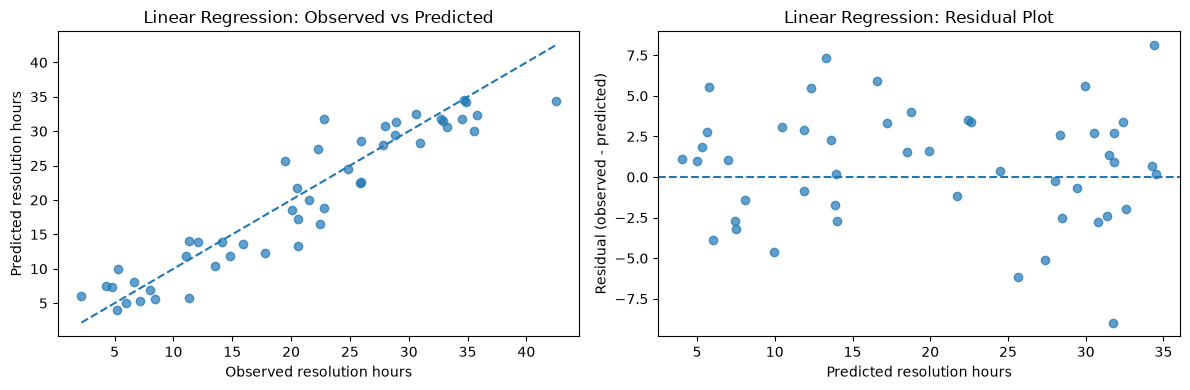

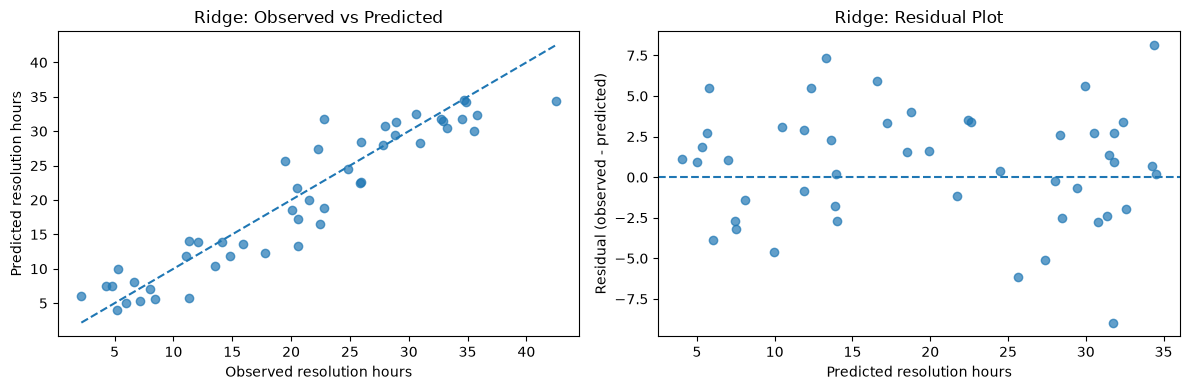

In [12]:
models_to_plot = {
    "Linear Regression": linear_predictions,
    "Ridge": ridge_predictions
}

for model_name, predictions in models_to_plot.items():
    residuals = y_test.to_numpy() - predictions

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # Observed vs. predicted
    axes[0].scatter(y_test, predictions, alpha=0.7)

    min_value = min(y_test.min(), predictions.min())
    max_value = max(y_test.max(), predictions.max())

    axes[0].plot(
        [min_value, max_value],
        [min_value, max_value],
        linestyle="--"
    )

    axes[0].set_title(f"{model_name}: Observed vs Predicted")
    axes[0].set_xlabel("Observed resolution hours")
    axes[0].set_ylabel("Predicted resolution hours")

    # Residual plot
    axes[1].scatter(predictions, residuals, alpha=0.7)
    axes[1].axhline(0, linestyle="--")

    axes[1].set_title(f"{model_name}: Residual Plot")
    axes[1].set_xlabel("Predicted resolution hours")
    axes[1].set_ylabel("Residual (observed - predicted)")

    plt.tight_layout()
    plt.show()

## 9. Final Recommendation

Ridge Regression achieved the lowest test RMSE (3.5721 hours) and MAE (2.9059 hours), with an R² of 0.8840. However, its performance was almost identical to ordinary Linear Regression and Lasso Regression.

Polynomial Regression did not improve performance, while the mean baseline performed poorly. Therefore, I would recommend Linear Regression as a simple, interpretable model, or Ridge Regression if the slightly lower error is preferred.

These results are promising for this synthetic dataset, but the model should be validated on real historical ticket data before being used in practice.

## 10. Analysis Questions

### 10.1 Is the baseline useful?

The mean baseline achieved an MAE of 9.1140 hours, an RMSE of 10.5977 hours, and an R² of -0.0210. Its performance was much worse than the regression models. This shows that using complexity and team experience provides useful predictive information in this dataset.

### 10.2 Which model achieved the lowest MAE and RMSE? Why might they differ?

Ridge Regression achieved the lowest MAE (2.9059 hours) and RMSE (3.5721 hours). However, the differences between Ridge, Linear Regression, and Lasso Regression were extremely small.

MAE measures the average absolute prediction error, while RMSE penalizes larger errors more heavily by squaring them before averaging. Therefore, the two metrics can rank models differently when their prediction errors differ in magnitude.

### 10.3 Did polynomial features improve performance? Is there evidence of overfitting?

No. Degree-2 Polynomial Regression achieved a test RMSE of 3.7409 hours, compared with 3.5723 hours for Linear Regression. Cross-validation also slightly favored degree 2 over degree 3, with mean RMSE values of 3.8325 and 3.8766 hours, respectively.

Polynomial features did not improve test performance. This suggests that the additional complexity was not useful here, although these results alone do not prove overfitting.

### 10.4 How did Ridge and Lasso affect performance and coefficients?

Ridge and Lasso achieved nearly identical performance to Linear Regression. The selected Ridge alpha was 0.1, while the selected Lasso alpha was 0.001.

Ridge coefficients were 8.9901 for `complexity_score` and -1.0773 for `team_experience_years`. Lasso coefficients were 8.9938 and -1.0768, respectively. These coefficients are based on standardized features.

The coefficients are very similar, indicating that the selected regularization strengths had little effect on their magnitudes. Ridge shrinks coefficients toward zero, while Lasso can shrink coefficients exactly to zero. The cross-validation results showed that stronger regularization increased error at larger alpha values, suggesting that excessive regularization can lead to underfitting.

### 10.5 Why should features be scaled for Ridge and Lasso?

Ridge and Lasso penalize coefficient sizes. If features have very different scales, the penalty can affect them unevenly. Standardizing the features makes their scales more comparable, allowing regularization to work more consistently.

### 10.6 What is data leakage, and how was it addressed?

Data leakage occurs when a model uses information that would not legitimately be available at prediction time. I excluded `ticket_id` because it is an identifier, and excluded `lines_changed` and `reopened` because they may only be known after work has begun or a ticket has been resolved.

This assumes the model predicts resolution time when a ticket is first received. If these features are genuinely available at that moment, their exclusion could be reconsidered.

### 10.7 Is a random train/test split always appropriate?

No. A random split can be inappropriate when tickets have a time-dependent pattern or when records from the same customer or team appear in both training and testing sets.

For predicting future tickets, a time-based split may better represent deployment. If the goal is to generalize to unseen customers or teams, a group-based split may be more suitable.

### 10.8 What additional tests are needed before deployment?

Before deployment, I would test the model on real historical ticket data and evaluate it using a time-based or group-based split where appropriate. I would also compare it against a baseline, inspect errors across ticket types and teams, check data quality and outliers, and monitor prediction errors and changes in the data over time.

Because the current dataset is synthetic, these results are not sufficient to establish real-world reliability.

In [13]:
print("Ridge coefficients:")
for feature, coef in zip(X.columns, ridge_model.named_steps["regression"].coef_):
    print(f"{feature}: {coef:.4f}")

print("\nLasso coefficients:")
for feature, coef in zip(X.columns, lasso_model.named_steps["regression"].coef_):
    print(f"{feature}: {coef:.4f}")

Ridge coefficients:
complexity_score: 8.9901
team_experience_years: -1.0773

Lasso coefficients:
complexity_score: 8.9938
team_experience_years: -1.0768
